# import les bibliothèques

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

from sklearn.preprocessing import MinMaxScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)


# Read dataset

In [3]:
def load_data():
    x_train = pd.read_csv("../traitement data/result/x_train.csv")
    y_train = pd.read_csv("../traitement data/result/y_train.csv")
    x_test = pd.read_csv("../traitement data/result/x_test.csv")
    y_test = pd.read_csv("../traitement data/result/y_test.csv")

    return x_train, y_train, x_test, y_test

In [4]:
x_train, y_train, x_test, y_test = load_data()

In [5]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(116468, 117)
(29117, 117)
(116468, 1)
(29117, 1)


In [6]:
y_train = y_train.values.ravel()
y_test = y_test.values.ravel()

# Model training

In [7]:
def train_model(x_train, y_train, x_test, y_test):
    models = {
        "Naives bayes": GaussianNB(),

        "Desision tree": DecisionTreeClassifier(
            criterion="entropy",
            max_depth=4
            ),

        "Random Forest": RandomForestClassifier(
            n_estimators=30
        ),

        "Svm": SVC(gamma="scale"),

        "Logistic Regression": LogisticRegression(max_iter=1200000),

        "Gradient Boosting": GradientBoostingClassifier(
            random_state=0
        )
    }

    results = []

    for name, model in models.items():

        print(f"\n Training {name}...")

        start = time.time()

        model.fit(x_train, y_train)

        train_time = time.time() -start 

        start = time.time()

        y_pred_test = model.predict(x_test)

        test_time = time.time() - start 

        accuracy = accuracy_score(y_test, y_pred_test)

        results.append({
            "Model": model,
            "Training time": train_time,
            "test time": test_time,
            "accuracy": accuracy
        })

        
    return pd.DataFrame(results)


In [ ]:
results = train_model(
    x_train,
    y_train,
    x_test,
    y_test
)


 Training Naives bayes...

 Training Desision tree...

 Training Random Forest...

 Training Svm...

 Training Logistic Regression...

 Training Gradient Boosting...


In [ ]:
df = pd.DataFrame(results)

In [ ]:
df.head()

,Model,Training time,test time,accuracy
0,GaussianNB(),0.178722,0.110968,0.620291
1,"DecisionTreeClassifier(criterion='entropy', ma...",0.277901,0.012399,0.979874
2,"(DecisionTreeClassifier(max_features='sqrt', r...",1.639350,0.056161,0.999313
3,SVC(),17.440634,2.790439,0.998180
4,LogisticRegression(max_iter=1200000),4.362732,0.012193,0.996600


# Model Comparison

In [ ]:
def comapre_model(results):

    plt.figure(figsize=(12, 6))

    model_names = [type(model).__name__ for model in results["Model"]]

    plt.bar(
        model_names,
        results["accuracy"]
    )

    plt.xlabel("Models")
    plt.ylabel("Accuracy")
    plt.title("Comparaison des modèles")
    plt.xticks(rotation=45)
    plt.show()

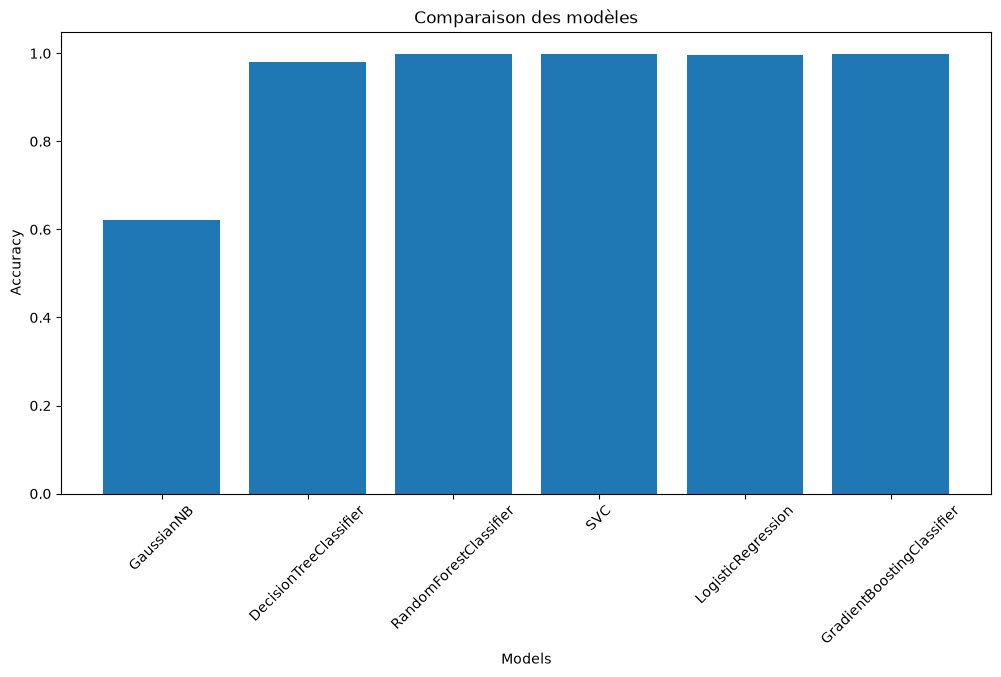

In [ ]:
comapre_model(results)

# Evaluation du meilleur modèle

In [ ]:
def evaluate_best_model(results):

    best_index = results["accuracy"].idxmax()

    best_model = results.loc[best_index, "Model"]

    print("Best model:", best_model)

    y_pred = best_model.predict(x_test)

    print(classification_report(y_pred, y_test))

    return best_model, y_pred

In [ ]:
model_final, y_pred = evaluate_best_model(results)

NameError: name 'evaluate_best_model' is not defined

In [ ]:
print("model: ", model_final)
print("y predict: ", y_pred)

model:  RandomForestClassifier(n_estimators=30)
y predict:  [0 1 0 ... 1 0 1]
